# Prepare Effluent NH3-N and NO3-N forecast training data

Load the training-safe Google Drive export, select the configured features, preserve operational nulls, and create chronological train/test splits. Effluent NH3-N uses ten-minute operating snapshots to predict the target one hour ahead; the split is purged by the forecast horizon to prevent temporal leakage.

The project prediction named `eff_nh3_n` uses `Eff_NH4_N` as its measured target. This notebook preserves that existing configuration and fits an initial XGBoost proof-of-concept without randomly shuffling time-series observations.


In [89]:
from pathlib import Path
import sys
import warnings

import pandas as pd

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "config" / "sensors.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch Jupyter from the repository root or notebooks directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.common import FORECAST_WINDOW
from config.eff_nh3_n import CONFIG as EFF_NH3_CONFIG
from config.eff_no3_n import CONFIG as EFF_NO3_CONFIG
from config.sensors import SENSORS


## Load and validate the saved dataset

`google_drive_filled.csv` is the shared all-sensor model source. This notebook resolves and selects exactly the 16 inputs checked in the **Eff NH3-N** column of `Sensor_Configurations.xlsx`, plus its target, through the application configuration. The companion mask confirms that targets were never interpolated. The requested interval is applied again here, and a warning identifies any part absent from the saved source data.


In [90]:
DATA_PATH = PROJECT_ROOT / "notebooks" / "data" / "google_drive_filled.csv"
MASK_PATH = PROJECT_ROOT / "notebooks" / "data" / "google_drive_fill_mask.csv"
TRAIN_FRACTION = 0.80
RESAMPLE_FREQUENCY = FORECAST_WINDOW["frequency"]
NH3_INPUT_FREQUENCY = "10min"
NH3_FORECAST_HORIZON = pd.Timedelta(hours=1)
START_TIME = "2026-04-02 13:40:00"
END_TIME = "2026-04-07 13:40:00"
requested_start = pd.Timestamp(START_TIME)
requested_end = pd.Timestamp(END_TIME)
if requested_start >= requested_end:
    raise ValueError("START_TIME must be earlier than END_TIME.")

data = pd.read_csv(DATA_PATH, encoding="utf-8-sig", parse_dates=["datetime"])
data = data.set_index("datetime").sort_index()
fill_mask = pd.read_csv(MASK_PATH, encoding="utf-8-sig", parse_dates=["datetime"])
fill_mask = fill_mask.set_index("datetime").sort_index()
fill_mask = fill_mask.apply(
    lambda column: column.astype(str).str.casefold().map({"true": True, "false": False})
)
if data.empty:
    raise ValueError(f"Training dataset is empty: {DATA_PATH}")
if not data.index.is_unique or not data.index.is_monotonic_increasing:
    raise ValueError("Training timestamps must be unique and sorted.")
if not data.index.equals(fill_mask.index) or list(data.columns) != list(fill_mask.columns):
    raise ValueError("Training data and imputation mask are not aligned.")
in_requested_window = (data.index >= requested_start) & (data.index < requested_end)
data = data.loc[in_requested_window].copy()
fill_mask = fill_mask.loc[in_requested_window].copy()
if data.empty:
    raise ValueError("The saved dataset has no rows in the requested time window.")
rows_with_values = data.notna().any(axis=1)
available_data = data.loc[rows_with_values]
if available_data.empty:
    raise ValueError("The requested window contains no observed or conservatively filled values.")
available_start, available_end = available_data.index.min(), available_data.index.max()
expected_minute_rows = len(pd.date_range(
    requested_start, requested_end, freq="1min", inclusive="left"
))
value_row_coverage = int(rows_with_values.sum()) / expected_minute_rows
expected_last_minute = requested_end - pd.Timedelta(minutes=1)
if available_start > requested_start or available_end < expected_last_minute:
    warnings.warn(
        "The saved data falls inside the requested window, but does not cover it fully. "
        f"Requested [{requested_start}, {requested_end}); available "
        f"[{available_start}, {available_end}]. Add the missing source readings and rerun notebook 02 "
        "before treating the forecast metrics as representative.",
        stacklevel=2,
    )
if fill_mask.isna().any().any():
    raise ValueError("The imputation mask contains values other than True or False.")
if not 0 < TRAIN_FRACTION < 1:
    raise ValueError("TRAIN_FRACTION must be between 0 and 1.")

print(f"Requested window: [{requested_start}, {requested_end})")
print(f"Loaded {len(data):,} rows and {len(data.columns)} sensors.")
print(f"Rows containing at least one usable value: {rows_with_values.sum():,} "
      f"({value_row_coverage:.1%} of the requested one-minute grid)")
print(f"Available value range: {available_start} through {available_end}")
print(f"Remaining feature nulls: {data.isna().sum().sum():,}")
print(f"Audited interpolated feature cells: {fill_mask.to_numpy().sum():,}")
print("Eff NH3-N columns are selected from this shared dataframe in the next step.")


Requested window: [2026-04-02 13:40:00, 2026-04-07 13:40:00)
Loaded 1,440 rows and 30 sensors.
Rows containing at least one usable value: 1,440 (20.0% of the requested one-minute grid)
Available value range: 2026-04-04 00:00:00 through 2026-04-04 23:59:00
Remaining feature nulls: 11,323
Audited interpolated feature cells: 110
Eff NH3-N columns are selected from this shared dataframe in the next step.


/Users/bryancastillo/Documents/projects/ao-mbr-data-pipeline/.venv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3823: UserWarning: The saved data falls inside the requested window, but does not cover it fully. Requested [2026-04-02 13:40:00, 2026-04-07 13:40:00); available [2026-04-04 00:00:00, 2026-04-04 23:59:00]. Add the missing source readings and rerun notebook 02 before treating the forecast metrics as representative.
  exec(code_obj, self.user_global_ns, self.user_ns)


## Resolve configured model columns

The model configurations use preferred aliases, while the CSV uses full tag names. Resolve them through `config.sensors` so this notebook stays synchronized with the application configuration.


In [91]:
MODEL_CONFIGS = {
    EFF_NH3_CONFIG["name"]: EFF_NH3_CONFIG,
    EFF_NO3_CONFIG["name"]: EFF_NO3_CONFIG,
}
MODEL_SOURCE_DATA = {model_name: data for model_name in MODEL_CONFIGS}
MODEL_SOURCE_MASKS = {model_name: fill_mask for model_name in MODEL_CONFIGS}
FULL_TAG_BY_ALIAS = {alias: sensor["fullTagName"] for alias, sensor in SENSORS.items()}

model_columns = {}
target_tags = []
for model_name, config in MODEL_CONFIGS.items():
    aliases = [*config["features"], config["target"]]
    unknown_aliases = [alias for alias in aliases if alias not in FULL_TAG_BY_ALIAS]
    if unknown_aliases:
        raise ValueError(f"{model_name} has unknown sensor aliases: {unknown_aliases}")
    tags = [FULL_TAG_BY_ALIAS[alias] for alias in aliases]
    source_data = MODEL_SOURCE_DATA[model_name]
    missing_tags = [tag for tag in tags if tag not in source_data.columns]
    if missing_tags:
        raise ValueError(f"{model_name} is missing CSV columns: {missing_tags}")
    feature_tags = [FULL_TAG_BY_ALIAS[alias] for alias in config["features"]]
    target_tag = FULL_TAG_BY_ALIAS[config["target"]]
    model_columns[model_name] = {
        "feature_aliases": list(config["features"]),
        "feature_tags": feature_tags,
        "target_alias": config["target"],
        "target_tag": target_tag,
    }
    target_tags.append(target_tag)

nh3_required_tags = [
    *model_columns[EFF_NH3_CONFIG["name"]]["feature_tags"],
    model_columns[EFF_NH3_CONFIG["name"]]["target_tag"],
]
nh3_selected_data = data.loc[:, nh3_required_tags].copy()
nh3_selected_mask = fill_mask.loc[:, nh3_required_tags].copy()
if list(nh3_selected_data.columns) != nh3_required_tags:
    raise AssertionError("Eff NH3-N selection is not in configured feature/target order.")
for model_name, columns in model_columns.items():
    if MODEL_SOURCE_MASKS[model_name][columns["target_tag"]].any():
        raise ValueError(f"{model_name} target was interpolated; refusing training.")

target_availability = pd.DataFrame({
    model_name: {
        "input_columns": len(columns["feature_tags"]),
        "observed_minute_rows": int(
            MODEL_SOURCE_DATA[model_name][columns["target_tag"]].notna().sum()
        ),
        "missing_minute_rows": int(
            MODEL_SOURCE_DATA[model_name][columns["target_tag"]].isna().sum()
        ),
    }
    for model_name, columns in model_columns.items()
}).T
nh3_columns = model_columns[EFF_NH3_CONFIG["name"]]
nh3_feature_audit = pd.DataFrame({
    "role": ["input feat"] * len(nh3_columns["feature_tags"]) + ["target"],
    "alias": [*nh3_columns["feature_aliases"], nh3_columns["target_alias"]],
    "full_tag": [*nh3_columns["feature_tags"], nh3_columns["target_tag"]],
})
print(f"Eff NH3-N selected {len(nh3_columns['feature_tags'])} configured inputs "
      f"plus target from the {len(data.columns)}-sensor shared dataframe.")

display(pd.DataFrame(model_columns).T[["target_alias", "target_tag"]])
display(target_availability)
display(nh3_feature_audit)


Eff NH3-N selected 16 configured inputs plus target from the 30-sensor shared dataframe.


,target_alias,target_tag
eff_nh3_n,Eff_NH4_N,70nh4_neffammonia
eff_no3_n,Eff_NO3_N,70no3_neffnitrate


,input_columns,observed_minute_rows,missing_minute_rows
eff_nh3_n,16,1426,14
eff_no3_n,21,1426,14


,role,alias,full_tag
0,input feat,A1_Qin,70flowa1qin
1,input feat,A2_Qin,70flowa2qin
2,input feat,A1_COD_in,70coda1inf
3,input feat,A2_COD_in,70coda2inf
4,input feat,A1_NH3_N,70nh3_na1nh3n
5,input feat,A2_NH3_N,70nh3_na2nh3n
6,input feat,A1_O_PH,70pha1aerobic
7,input feat,A1_O_ORP,70orpa1aerobic
8,input feat,A1_O_DO,70doa1aerobic
9,input feat,A1_O_MLSS,70mlssa1aerobic


## Build operational-state-aware model datasets

For Effluent NH3-N, aggregate the checked sensors into ten-minute operating snapshots and predict the target one hour later. Preserve inactive-zone `NaN` values for XGBoost's native missing-value routing, and add an availability fraction derived from each checked sensor so valve/stream switching remains an explicit signal. The current observed effluent value is included as an autoregressive input available at forecast creation time. Only rows missing the future target—or every checked input—are removed.

The NO3 preparation remains at the configured hourly cadence for later development. No unlisted sensor is introduced; availability fields are derived solely from the workbook-checked NH3 inputs.


In [92]:
model_datasets = {}
for model_name, columns in model_columns.items():
    source_data = MODEL_SOURCE_DATA[model_name]
    source_mask = MODEL_SOURCE_MASKS[model_name]
    feature_tags = columns["feature_tags"]
    feature_aliases = columns["feature_aliases"]
    target_tag = columns["target_tag"]
    target_alias = columns["target_alias"]

    if model_name == EFF_NH3_CONFIG["name"]:
        step = pd.Timedelta(NH3_INPUT_FREQUENCY)
        if NH3_FORECAST_HORIZON % step:
            raise ValueError("NH3_FORECAST_HORIZON must be divisible by NH3_INPUT_FREQUENCY.")
        horizon_steps = int(NH3_FORECAST_HORIZON / step)
        feature_means = source_data[feature_tags].resample(NH3_INPUT_FREQUENCY).mean()
        feature_means.columns = feature_aliases
        feature_availability = (
            source_data[feature_tags].notna().resample(NH3_INPUT_FREQUENCY).mean()
        )
        availability_columns = [f"{alias}__availability" for alias in feature_aliases]
        feature_availability.columns = availability_columns
        current_target_column = f"{target_alias}__current"
        current_target = source_data[target_tag].resample(NH3_INPUT_FREQUENCY).mean()
        current_target = current_target.rename(current_target_column)
        future_target = current_target.shift(-horizon_steps).rename(target_alias)
        model_frame = pd.concat(
            [feature_means, feature_availability, current_target, future_target], axis=1
        )
        usable = future_target.notna() & feature_means.notna().any(axis=1)
        model_frame = model_frame.loc[usable].copy()
        # Index rows by the time being forecast, not by the feature-window start.
        model_frame.index = model_frame.index + NH3_FORECAST_HORIZON
        input_columns = [*feature_aliases, *availability_columns, current_target_column]
        model_mask = source_mask[feature_tags].resample(NH3_INPUT_FREQUENCY).max()
        model_mask = model_mask.loc[usable].copy()
        model_mask.index = model_mask.index + NH3_FORECAST_HORIZON
        model_mask.columns = feature_aliases
        cadence = NH3_INPUT_FREQUENCY
        horizon = NH3_FORECAST_HORIZON
    else:
        required_tags = [*feature_tags, target_tag]
        alias_by_tag = dict(zip(required_tags, [*feature_aliases, target_alias]))
        hourly_data = source_data.resample(RESAMPLE_FREQUENCY).mean()
        hourly_imputed = source_mask.resample(RESAMPLE_FREQUENCY).max().astype(bool)
        model_frame = hourly_data[required_tags].rename(columns=alias_by_tag).dropna()
        model_mask = hourly_imputed.loc[model_frame.index, feature_tags]
        model_mask = model_mask.rename(columns=dict(zip(feature_tags, feature_aliases)))
        input_columns = feature_aliases
        cadence = RESAMPLE_FREQUENCY
        horizon = pd.Timedelta(0)

    if len(model_frame) < 2:
        raise ValueError(f"{model_name} needs at least two usable rows.")
    model_datasets[model_name] = {
        "data": model_frame, "imputation_mask": model_mask,
        "input_columns": input_columns, "cadence": cadence, "horizon": horizon,
    }

for model_name, prepared in model_datasets.items():
    print(
        f"{model_name}: {len(prepared['data'])} usable rows at {prepared['cadence']}; "
        f"horizon={prepared['horizon']}; "
        f"{prepared['imputation_mask'].any(axis=1).sum()} rows include a safely filled feature"
    )


eff_nh3_n: 138 usable rows at 10min; horizon=0 days 01:00:00; 28 rows include a safely filled feature
eff_no3_n: 24 usable rows at 1h; horizon=0 days 00:00:00; 17 rows include a safely filled feature


## Chronological 80/20 split

Keep the earliest observations for training and the latest 20% for testing without shuffling. For NH3, purge the one-hour horizon immediately before the test segment: every retained training label must be observable by the time the first test forecast is created. This prevents overlapping forecast windows from leaking future target information across the split. The single available day still makes this an experimental validation, not a production accuracy estimate.


In [93]:
splits = {}
split_records = []

for model_name, prepared in model_datasets.items():
    model_frame = prepared["data"]
    columns = model_columns[model_name]
    input_columns = prepared["input_columns"]
    split_position = int(len(model_frame) * TRAIN_FRACTION)
    split_position = min(max(split_position, 1), len(model_frame) - 1)

    test_frame = model_frame.iloc[split_position:].copy()
    if prepared["horizon"] > pd.Timedelta(0):
        first_test_origin = test_frame.index.min() - prepared["horizon"]
        train_frame = model_frame.loc[model_frame.index <= first_test_origin].copy()
    else:
        train_frame = model_frame.iloc[:split_position].copy()
    if train_frame.empty:
        raise ValueError(f"{model_name} has no rows after horizon purging.")

    X_train = train_frame[input_columns]
    y_train = train_frame[columns["target_alias"]]
    X_test = test_frame[input_columns]
    y_test = test_frame[columns["target_alias"]]

    splits[model_name] = {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
    }
    split_records.append({
        "model": model_name,
        "target": columns["target_alias"],
        "model_inputs": len(input_columns),
        "checked_sensor_inputs": len(columns["feature_aliases"]),
        "cadence": prepared["cadence"],
        "forecast_horizon": prepared["horizon"],
        "train_rows": len(train_frame),
        "test_rows": len(test_frame),
        "train_start": train_frame.index.min(),
        "train_end": train_frame.index.max(),
        "test_start": test_frame.index.min(),
        "test_end": test_frame.index.max(),
        "target_unique_train": y_train.nunique(),
        "target_unique_test": y_test.nunique(),
    })

split_summary = pd.DataFrame(split_records).set_index("model")
display(split_summary)


,target,model_inputs,checked_sensor_inputs,cadence,forecast_horizon,train_rows,test_rows,train_start,train_end,test_start,test_end,target_unique_train,target_unique_test
model,,,,,,,,,,,,,
eff_nh3_n,Eff_NH4_N,33,16,10min,0 days 01:00:00,105,28,2026-04-04 01:00:00,2026-04-04 18:20:00,2026-04-04 19:20:00,2026-04-04 23:50:00,104,28
eff_no3_n,Eff_NO3_N,21,21,1h,0 days 00:00:00,19,5,2026-04-04 00:00:00,2026-04-04 18:00:00,2026-04-04 19:00:00,2026-04-04 23:00:00,1,1


## Convenient split variables

Expose explicit variables for the next modeling notebook cells while retaining the `splits` dictionary for reusable model loops. A constant NO3 target is accepted as observed real-world data; it will produce a constant baseline until more varied observations become available.


In [94]:
X_train_nh3 = splits["eff_nh3_n"]["X_train"]
X_test_nh3 = splits["eff_nh3_n"]["X_test"]
y_train_nh3 = splits["eff_nh3_n"]["y_train"]
y_test_nh3 = splits["eff_nh3_n"]["y_test"]

X_train_no3 = splits["eff_no3_n"]["X_train"]
X_test_no3 = splits["eff_no3_n"]["X_test"]
y_train_no3 = splits["eff_no3_n"]["y_train"]
y_test_no3 = splits["eff_no3_n"]["y_test"]

print("Effluent NH3-N split:", X_train_nh3.shape, X_test_nh3.shape)
print("Effluent NO3-N split:", X_train_no3.shape, X_test_no3.shape)
if y_train_no3.nunique() == 1:
    print(f"NO3 target is constant at {y_train_no3.iloc[0]:g}; retain a constant baseline.")


Effluent NH3-N split: (105, 33) (28, 33)
Effluent NO3-N split: (19, 21) (5, 21)
NO3 target is constant at 5; retain a constant baseline.


## Train an XGBoost model for Effluent NH3-N

Fit a regularized gradient-boosted tree model on the purged chronological training window only. XGBoost retains inactive-zone `NaN` values and learns a default branch for them; availability ratios describe how much of each ten-minute input window was active. The latest observed effluent value provides the one-hour persistence baseline. Test observations are reserved strictly for evaluation.

> This is now a genuine one-hour-ahead proof of concept, but all samples still come from one calendar day. Ten-minute windows provide more operating snapshots, not independent days, so the reported metrics remain preliminary.

Evaluate both magnitude and consistency of the held-out errors. MAE, median absolute error, RMSE, and maximum error use the original mg-N/L scale; MAPE, sMAPE, WAPE, and normalized RMSE provide relative error; bias and residual standard deviation describe calibration and precision; R², explained variance, and Pearson correlation describe trend agreement. Tolerance accuracy reports the percentage of forecasts within ±0.005 and ±0.010 mg-N/L. Skill scores quantify improvement over the current-value persistence baseline.


In [95]:
import numpy as np
from sklearn.metrics import (
    explained_variance_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)
from xgboost import XGBRegressor

XGB_NH3_PARAMETERS = {
    "objective": "reg:squarederror",
    "n_estimators": 300,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 2,
    "subsample": 0.85,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 2.0,
    "random_state": 42,
    "n_jobs": 1,
}

xgb_nh3_model = XGBRegressor(**XGB_NH3_PARAMETERS)
xgb_nh3_model.fit(X_train_nh3, y_train_nh3)

nh3_xgb_prediction = pd.Series(
    xgb_nh3_model.predict(X_test_nh3), index=y_test_nh3.index, name="xgboost"
)
current_target_column = f"{EFF_NH3_CONFIG['target']}__current"
nh3_persistence_prediction = X_test_nh3[current_target_column].ffill().copy()
if nh3_persistence_prediction.isna().any():
    last_training_target = X_train_nh3[current_target_column].dropna().iloc[-1]
    nh3_persistence_prediction = nh3_persistence_prediction.fillna(last_training_target)
nh3_persistence_prediction.name = "current_value_baseline"
nh3_test_results = pd.concat(
    [y_test_nh3.rename("actual"), nh3_xgb_prediction, nh3_persistence_prediction], axis=1
)

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    residual = predicted - actual
    absolute_error = np.abs(residual)
    squared_error = residual ** 2
    safe_actual = np.maximum(np.abs(actual), np.finfo(float).eps)
    smape_denominator = np.maximum(
        (np.abs(actual) + np.abs(predicted)) / 2, np.finfo(float).eps
    )
    pearson_r = (np.corrcoef(actual, predicted)[0, 1]
                 if np.std(actual) > 0 and np.std(predicted) > 0 else np.nan)
    residual_lag1_r = pd.Series(residual).autocorr(lag=1)
    rmse = mean_squared_error(actual, predicted) ** 0.5
    return {
        "N": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "MedianAE": median_absolute_error(actual, predicted),
        "MSE": np.mean(squared_error),
        "RMSE": rmse,
        "MaxAE": np.max(absolute_error),
        "Bias": np.mean(residual),
        "ResidualSD": np.std(residual, ddof=1),
        "MAPE_pct": np.mean(absolute_error / safe_actual) * 100,
        "sMAPE_pct": np.mean(absolute_error / smape_denominator) * 100,
        "WAPE_pct": absolute_error.sum() / safe_actual.sum() * 100,
        "NRMSE_mean_pct": rmse / np.mean(safe_actual) * 100,
        "R2": r2_score(actual, predicted),
        "ExplainedVariance": explained_variance_score(actual, predicted),
        "PearsonR": pearson_r,
        "ResidualLag1R": residual_lag1_r,
        "Within_0.005_pct": np.mean(absolute_error <= 0.005) * 100,
        "Within_0.010_pct": np.mean(absolute_error <= 0.010) * 100,
    }

nh3_metrics = pd.DataFrame({
    "XGBoost": regression_metrics(y_test_nh3, nh3_xgb_prediction),
    "Current-value baseline": regression_metrics(y_test_nh3, nh3_persistence_prediction),
}).T
nh3_skill = pd.DataFrame({
    "XGBoost improvement vs current-value baseline (%)": {
        "MAE skill": 100 * (1 - nh3_metrics.loc["XGBoost", "MAE"]
                              / nh3_metrics.loc["Current-value baseline", "MAE"]),
        "RMSE skill": 100 * (1 - nh3_metrics.loc["XGBoost", "RMSE"]
                               / nh3_metrics.loc["Current-value baseline", "RMSE"]),
    }
})
absolute_metric_columns = ["MAE", "MedianAE", "MSE", "RMSE", "MaxAE", "Bias", "ResidualSD"]
relative_metric_columns = [
    "MAPE_pct", "sMAPE_pct", "WAPE_pct", "NRMSE_mean_pct",
    "Within_0.005_pct", "Within_0.010_pct",
]
relationship_metric_columns = [
    "R2", "ExplainedVariance", "PearsonR", "ResidualLag1R",
]
display(nh3_metrics[["N", *absolute_metric_columns]].style.format(precision=6))
display(nh3_metrics[relative_metric_columns].style.format("{:.2f}%"))
display(nh3_metrics[relationship_metric_columns].style.format("{:.3f}"))
display(nh3_skill.style.format("{:.2f}%"))
display(nh3_test_results)


,N,MAE,MedianAE,MSE,RMSE,MaxAE,Bias,ResidualSD
XGBoost,28.000000,0.005066,0.004388,0.000037,0.006043,0.013899,-0.001241,0.006023
Current-value baseline,28.000000,0.006310,0.004732,0.000070,0.008359,0.020174,-0.000551,0.008494


,MAPE_pct,sMAPE_pct,WAPE_pct,NRMSE_mean_pct,Within_0.005_pct,Within_0.010_pct
XGBoost,2.67%,2.68%,2.68%,3.19%,64.29%,92.86%
Current-value baseline,3.33%,3.35%,3.34%,4.42%,53.57%,78.57%


,R2,ExplainedVariance,PearsonR,ResidualLag1R
XGBoost,-0.219,-0.167,0.021,-0.281
Current-value baseline,-1.332,-1.322,-0.232,-0.210


,XGBoost improvement vs current-value baseline (%)
MAE skill,19.71%
RMSE skill,27.71%


,actual,xgboost,current_value_baseline
datetime,,,
2026-04-04 19:20:00,0.186060,0.190921,0.180726
2026-04-04 19:30:00,0.194020,0.186063,0.187300
2026-04-04 19:40:00,0.183900,0.187986,0.187889
2026-04-04 19:50:00,0.194572,0.190676,0.195041
2026-04-04 20:00:00,0.196027,0.189907,0.182100
2026-04-04 20:10:00,0.188060,0.188581,0.190060
2026-04-04 20:20:00,0.190480,0.188355,0.186060
2026-04-04 20:30:00,0.184020,0.184404,0.194020
2026-04-04 20:40:00,0.192290,0.182451,0.183900


In [96]:
# Dedicated Effluent NH3-N model-evaluation dashboard.
# Run the XGBoost training cell above first to create nh3_metrics and nh3_skill.
metric_catalog = pd.DataFrame([
    ("N", "Sample size", "count", "More test periods improve confidence"),
    ("MAE", "Absolute accuracy", "mg-N/L", "Lower is better"),
    ("MedianAE", "Typical absolute error", "mg-N/L", "Lower is better; robust to outliers"),
    ("MSE", "Squared error", "(mg-N/L)^2", "Lower is better; penalizes large errors"),
    ("RMSE", "Large-error-sensitive accuracy", "mg-N/L", "Lower is better"),
    ("MaxAE", "Worst held-out error", "mg-N/L", "Lower is better"),
    ("Bias", "Mean signed error", "mg-N/L", "Closer to zero is better"),
    ("ResidualSD", "Error precision / spread", "mg-N/L", "Lower is better"),
    ("MAPE_pct", "Mean absolute percentage error", "%", "Lower is better"),
    ("sMAPE_pct", "Symmetric percentage error", "%", "Lower is better"),
    ("WAPE_pct", "Volume-weighted absolute error", "%", "Lower is better"),
    ("NRMSE_mean_pct", "RMSE normalized by target mean", "%", "Lower is better"),
    ("R2", "Variance fit", "score", "Closer to 1 is better"),
    ("ExplainedVariance", "Explained target variation", "score", "Closer to 1 is better"),
    ("PearsonR", "Linear trend agreement", "correlation", "Closer to 1 is better"),
    ("ResidualLag1R", "Consecutive-error dependence", "correlation", "Closer to zero is better"),
    ("Within_0.005_pct", "Forecasts within +/-0.005 mg-N/L", "%", "Higher is better"),
    ("Within_0.010_pct", "Forecasts within +/-0.010 mg-N/L", "%", "Higher is better"),
], columns=["metric", "meaning", "unit", "interpretation"]).set_index("metric")

model_evaluation_table = metric_catalog.join(nh3_metrics.T)
display(
    model_evaluation_table.style
    .format({"XGBoost": "{:.6f}", "Current-value baseline": "{:.6f}"}, na_rep="n/a")
    .set_caption("Effluent NH3-N held-out model evaluation")
)
display(
    nh3_skill.style
    .format("{:.2f}%")
    .set_caption("Positive skill means XGBoost improves on persistence")
)


,meaning,unit,interpretation,XGBoost,Current-value baseline
metric,,,,,
N,Sample size,count,More test periods improve confidence,28.000000,28.000000
MAE,Absolute accuracy,mg-N/L,Lower is better,0.005066,0.006310
MedianAE,Typical absolute error,mg-N/L,Lower is better; robust to outliers,0.004388,0.004732
MSE,Squared error,(mg-N/L)^2,Lower is better; penalizes large errors,0.000037,0.000070
RMSE,Large-error-sensitive accuracy,mg-N/L,Lower is better,0.006043,0.008359
MaxAE,Worst held-out error,mg-N/L,Lower is better,0.013899,0.020174
Bias,Mean signed error,mg-N/L,Closer to zero is better,-0.001241,-0.000551
ResidualSD,Error precision / spread,mg-N/L,Lower is better,0.006023,0.008494
MAPE_pct,Mean absolute percentage error,%,Lower is better,2.666745,3.333543


,XGBoost improvement vs current-value baseline (%)
MAE skill,19.71%
RMSE skill,27.71%


## Actual versus predicted Effluent NH3-N

The left panel focuses on the available 4–5 April interval. It shows every available one-hour-ahead target and overlays predictions only where the purged chronological test set exists. The right panel compares each held-out XGBoost prediction with its observed value. Points on the diagonal would be exact predictions, while the current-value line is the one-hour persistence baseline.


Saved comparison figure: /Users/bryancastillo/Documents/projects/ao-mbr-data-pipeline/notebooks/data/effluent_nh3_xgboost_actual_vs_predicted.png


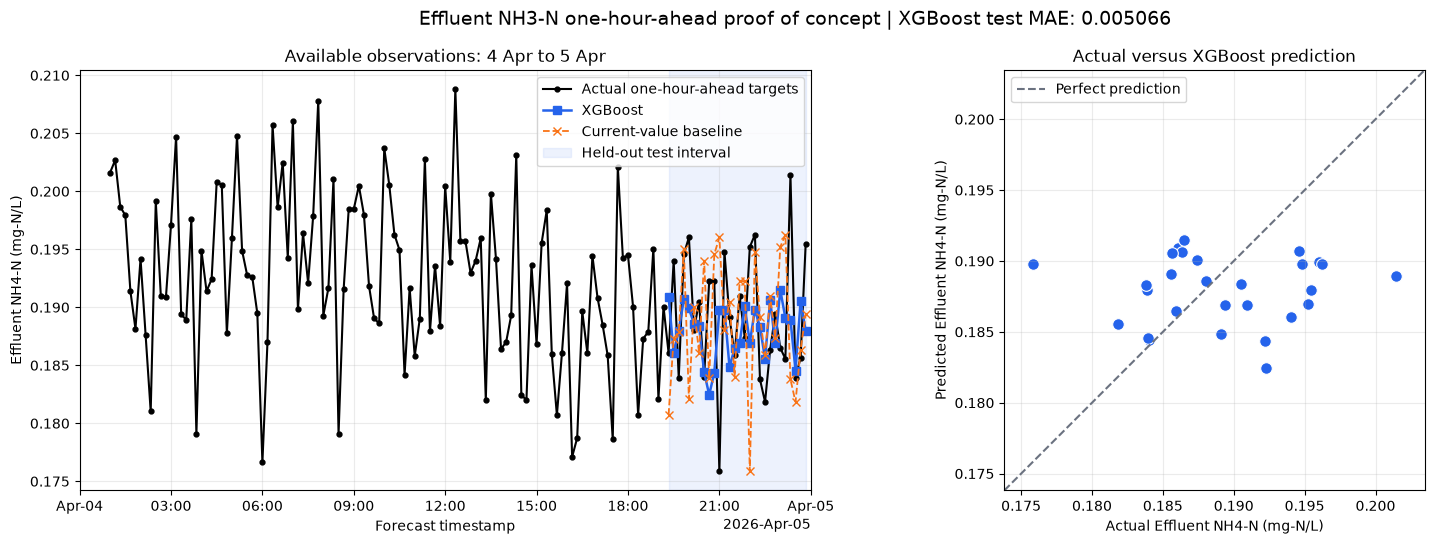

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

NH3_COMPARISON_FIGURE_PATH = (
    PROJECT_ROOT / "notebooks" / "data"
    / "effluent_nh3_xgboost_actual_vs_predicted.png"
)
nh3_all_actual = model_datasets["eff_nh3_n"]["data"][EFF_NH3_CONFIG["target"]]

fig, (time_ax, scatter_ax) = plt.subplots(1, 2, figsize=(16, 5.5))
time_ax.plot(nh3_all_actual.index, nh3_all_actual,
             marker="o", markersize=3.5, linewidth=1.5, color="black",
             label="Actual one-hour-ahead targets")
time_ax.plot(nh3_test_results.index, nh3_test_results["xgboost"],
             marker="s", linewidth=1.8, color="#2563eb", label="XGBoost")
time_ax.axvspan(y_test_nh3.index.min(), y_test_nh3.index.max(),
                color="#2563eb", alpha=0.08, label="Held-out test interval")
plot_start = available_start.floor("D")
plot_end = available_end.ceil("D")
if plot_end <= plot_start:
    plot_end = available_end + pd.Timedelta(minutes=1)
time_ax.set_xlim(plot_start, plot_end)
time_ax.xaxis.set_major_locator(mdates.AutoDateLocator())
time_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(time_ax.xaxis.get_major_locator()))
time_ax.set_title("Available observations: 4 Apr to 5 Apr")
time_ax.set_xlabel("Forecast timestamp")
time_ax.set_ylabel("Effluent NH4-N (mg-N/L)")
time_ax.grid(True, alpha=0.25)
time_ax.legend()

scatter_ax.scatter(nh3_test_results["actual"], nh3_test_results["xgboost"],
                   s=70, color="#2563eb", edgecolor="white", linewidth=0.8)
comparison_min = min(nh3_test_results["actual"].min(), nh3_test_results["xgboost"].min())
comparison_max = max(nh3_test_results["actual"].max(), nh3_test_results["xgboost"].max())
comparison_padding = max((comparison_max - comparison_min) * 0.08, 1e-6)
comparison_limits = (comparison_min - comparison_padding, comparison_max + comparison_padding)
scatter_ax.plot(comparison_limits, comparison_limits, linestyle="--", color="#6b7280",
                label="Perfect prediction")
scatter_ax.set_xlim(comparison_limits)
scatter_ax.set_ylim(comparison_limits)
scatter_ax.set_aspect("equal", adjustable="box")
scatter_ax.set_title("Actual versus XGBoost prediction")
scatter_ax.set_xlabel("Actual Effluent NH4-N (mg-N/L)")
scatter_ax.set_ylabel("Predicted Effluent NH4-N (mg-N/L)")
scatter_ax.grid(True, alpha=0.25)
scatter_ax.legend()

fig.suptitle(
    f"Effluent NH3-N one-hour-ahead proof of concept | "
    f"XGBoost test MAE: {nh3_metrics.loc['XGBoost', 'MAE']:.6f}",
    fontsize=14,
)
fig.tight_layout()
NH3_COMPARISON_FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(NH3_COMPARISON_FIGURE_PATH, dpi=180, bbox_inches="tight", facecolor="white")
print(f"Saved comparison figure: {NH3_COMPARISON_FIGURE_PATH}")
plt.show()
